# Workbook Exercise: Breast Cancer Diagnosis — An End-to-End Classification Project

**Course:** Machine Learning / Applied AI  **Level:** Intermediate  **Estimated time:** 2 hours

**Learning objectives.** By the end of this workbook you will be able to:
1. Frame a real-world problem as a supervised learning task.
2. Summarize and visualize a dataset to understand its structure before modeling.
3. Clean data, select informative features and apply appropriate transforms.
4. Build a leak-free test harness and spot-check several algorithms.
5. Improve accuracy through tuning and ensembles, then report honest test results.

**How to use this workbook.** Run the cells in order. Wherever you see `# TODO`, replace the `...` with your own code (hints are given). Cells marked ✏️ ask for a written answer: double-click to edit. Do not look at the answer key until you have tried each exercise.

**Outline**
- A. Problem Definition
- B. Summarize and Analyze Data
- C. Prepare Data
- D. Evaluate Algorithm
- E. Improve Accuracy



## Before you begin

> First, make a copy of this notebook so that you can make changes as you please.
> Run and edit the copy instead of this original notebook.

> To copy this notebook, go to `File|Save a Copy to Drive`.

**Gentle Reminder**
> Once finish, Kindly `push` this notebook to your GitHub repo.**

---
## A. Problem Definition

### A.1 Brief Description
The **Breast Cancer Wisconsin (Diagnostic)** dataset contains measurements computed from digitized images of fine-needle aspirates (FNA) of breast masses. Each row describes the characteristics of the cell nuclei present in one image.

- **569 instances**, **30 numeric features**, **1 binary target**
- Features are 10 nucleus measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each reported as the **mean**, the **standard error** and the **worst** (largest) value.
- Target: `0` = malignant, `1` = benign.

### A.2 Problem Statement
✏️ **Exercise A.1.** In 3–4 sentences, write a problem statement in your own words. Include: (a) the prediction task, (b) the input data, (c) the type of learning problem, (d) which kind of error is more costly and why, and (e) how you will judge success.

> **Your answer:** This project aims to predict whether a breast tumor is malignant or benign using 30 numeric features extracted from FNA images of cell nuclei. It is a supervised binary classification problem because the target variable has two possible outcomes. A false negative is more costly than a false positive because incorrectly classifying a malignant tumor as benign may delay medical treatment. Success will be evaluated using accuracy, F1-score, and recall, with particular emphasis on correctly identifying malignant cases.

### A.3 Load Packages
**Exercise A.2.** The imports below are mostly done. Add the classifier imports you will need in Parts C–E.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, cross_validate, GridSearchCV)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, make_scorer, recall_score)

# TODO: import LogisticRegression, LinearDiscriminantAnalysis, KNeighborsClassifier, DecisionTreeClassifier, GaussianNB, SVC, RandomForest, ExtraTrees, GradientBoosting, AdaBoost and VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier, AdaBoostClassifier, VotingClassifier

try:
    display
except NameError:
    display = print

try:
    display
except NameError:
    display = print

### A.4 Load Dataset
**Exercise A.3.** Load the data into a DataFrame named `df` (hint: `load_breast_cancer(as_frame=True)`).



> `url = [https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic]`

In [ ]:
# TODO: load the dataset and copy its DataFrame into df
data = load_breast_cancer(as_frame=True)
df = data.frame
print("Rows, columns:", df.shape)
print("Classes:", list(data.target_names), "-> 0 = malignant, 1 = benign")

Rows, columns: (569, 31)
Classes: [np.str_('malignant'), np.str_('benign')] -> 0 = malignant, 1 = benign


---
## B. Summarize and Analyze Data

### B.1 Descriptive Statistics
**Exercise B.1.** Inspect the dataset's dimensions, data types and the first rows.

In [ ]:
# TODO: print the shape, the counts of each dtype, and show the first 5 rows
print(df.shape)
print(df.dtypes.value_counts())
df.head()

(569, 31)
float64    30
int64       1
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


**Exercise B.2.** Check for class imbalance. Print the count and the proportion of each class.

In [ ]:
# TODO: class counts and percentages
print(df["target"].value_counts())
print(df["target"].value_counts(normalize=True))

target
1    357
0    212
Name: count, dtype: int64
target
1    0.627417
0    0.372583
Name: proportion, dtype: float64


**Exercise B.3.** Produce summary statistics (transposed so features are rows) and list the 10 most skewed features.

In [ ]:
# TODO: describe().T, then the 10 largest skewness values
display(df.describe().T)

print("\n10 most skewed features:")
print(df.drop(columns=["target"]).skew().sort_values(ascending=False).head(10))

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744



10 most skewed features:
area error                 5.447186
concavity error            5.110463
fractal dimension error    3.923969
perimeter error            3.443615
radius error               3.088612
smoothness error           2.314450
symmetry error             2.195133
compactness error          1.902221
worst area                 1.859373
worst fractal dimension    1.662579
dtype: float64


**Exercise B.4.** Compute the correlation of every feature with the target and show the 5 most negative and 5 most positive.

In [ ]:
# TODO: correlation with target, sorted
display(df.corr()["target"].sort_values(ascending=False))
print("\n5 most negative:")
print(df.corr()["target"].sort_values(ascending=False).tail(5))
print("\n5 most positive:")
print(df.corr()["target"].sort_values(ascending=False).head(5))

,target
target,1.000000
smoothness error,0.067016
mean fractal dimension,0.012838
texture error,0.008303
symmetry error,0.006522
fractal dimension error,-0.077972
concavity error,-0.253730
compactness error,-0.292999
worst fractal dimension,-0.323872
mean symmetry,-0.330499



5 most negative:
mean perimeter         -0.742636
worst radius           -0.776454
mean concave points    -0.776614
worst perimeter        -0.782914
worst concave points   -0.793566
Name: target, dtype: float64

5 most positive:
target                    1.000000
smoothness error          0.067016
mean fractal dimension    0.012838
texture error             0.008303
symmetry error            0.006522
Name: target, dtype: float64


✏️ **Question B.5.** What do the class proportions and the skewness tell you about the choice of evaluation metric and the need for transforms?

> **Your answer:** Your answer: The class proportions help determine whether accuracy is a reliable evaluation metric or if metrics like precision, recall, and F1-score are needed due to class imbalance. Meanwhile, skewness indicates how asymmetric the feature distributions are. Features with high skewness may require transformations, such as log transformations, to reduce the effect of outliers and improve model performance. Therefore, class balance influences metric selection, while skewness guides the need for data transformations.

### B.2 Data Visualization

**Exercise B.6 (univariate).** Plot histograms of the ten `mean` features.

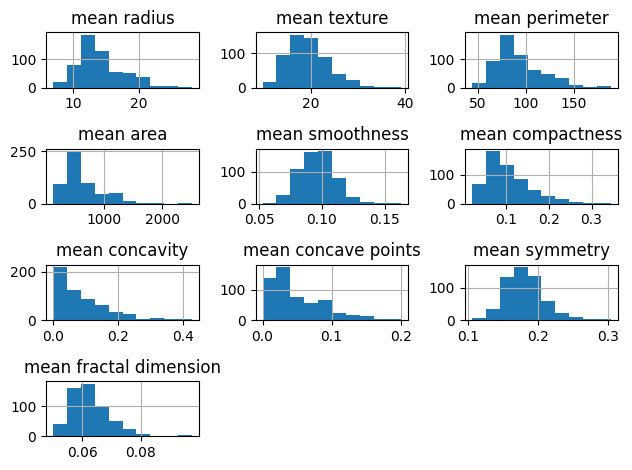

In [ ]:
# TODO: histograms of the ten "mean" features (hint: df.filter(like="mean").hist)
df.filter(like="mean").hist()
plt.tight_layout()
plt.show()

**Exercise B.7 (bivariate).** Draw box plots of four features split by class. Which separate the classes best?

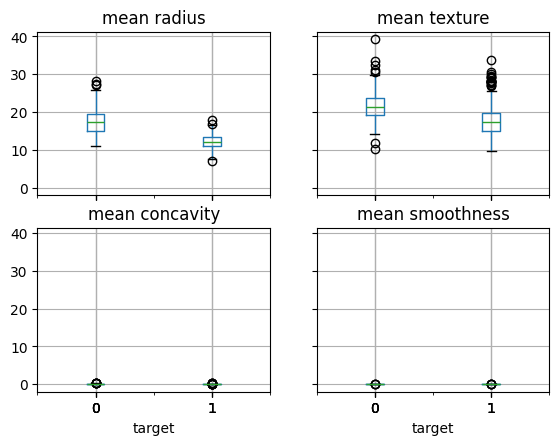

In [ ]:
features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]
# TODO: one box plot per feature, grouped by target
df.boxplot(column=features, by="target")
plt.suptitle("")
plt.show()


**Exercise B.8 (multivariate).** Show a correlation heatmap of the ten `mean` features.

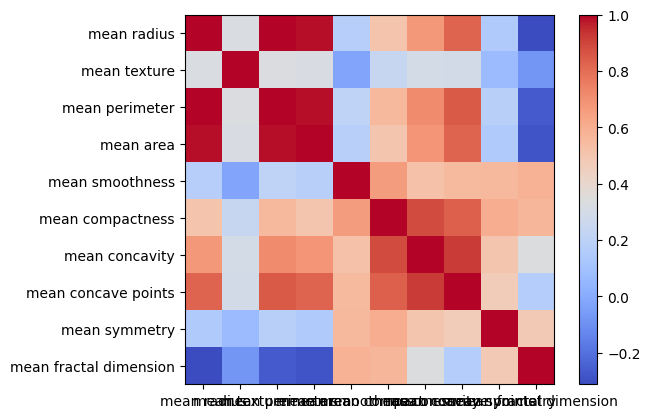

In [ ]:
# TODO: correlation matrix of the "mean" features drawn with imshow
plt.imshow(df.filter(like="mean").corr(), cmap="coolwarm")
plt.colorbar()
plt.xticks(np.arange(len(df.filter(like="mean").columns)), df.filter(like="mean").columns)
plt.yticks(np.arange(len(df.filter(like="mean").columns)), df.filter(like="mean").columns)
plt.show()

**Exercise B.9.** Scatter `mean radius` against `mean concavity`, coloured by class.

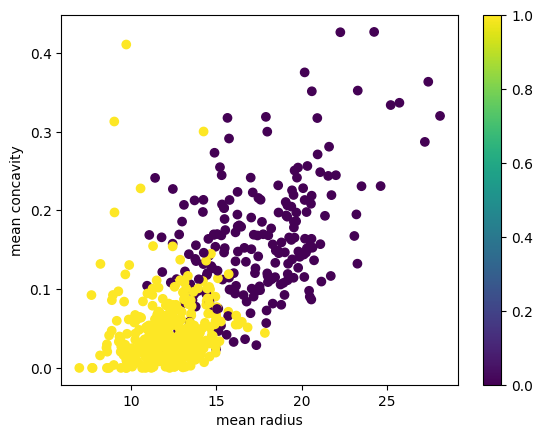

In [ ]:
# TODO: coloured scatter plot with axis labels and a colourbar
plt.scatter(df["mean radius"], df["mean concavity"], c=df["target"])
plt.xlabel("mean radius")
plt.ylabel("mean concavity")
plt.colorbar()
plt.show()

✏️ **Question B.10.** Which features appear redundant, and which separate the classes most clearly?

> **Your answer:** Several features appear redundant because they are highly correlated and measure similar characteristics, such as radius, perimeter, and area (including their mean, standard error, and worst values). These features tend to move together and provide overlapping information. Features such as worst concave points, worst perimeter, worst radius, and worst area appear to separate the benign and malignant classes most clearly because their values show distinct differences between the two groups. This suggests they are among the most important predictors for classification.

---
## C. Prepare Data

### C.1 Data Cleaning
**Exercise C.1.** Count missing values and duplicate rows.

In [ ]:
# TODO: total missing values and duplicated rows
print(df.isna().sum().sum())
print(df.duplicated().sum())

X = df.drop(columns="target")
y = df["target"]

0
0


**Exercise C.2.** Count outliers per feature using the IQR rule (below Q1 − 1.5·IQR or above Q3 + 1.5·IQR) and show the 10 features with the most.

In [ ]:
# TODO: IQR outlier count per feature
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1
outliers = ((df < (Q1 - 1.5 * IQR)) | (df > (Q3 + 1.5 * IQR))).sum()
print(outliers.sort_values(ascending=False).head(10))

area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
compactness error          28
fractal dimension error    28
symmetry error             27
mean area                  25
worst fractal dimension    24
dtype: int64


✏️ **Question C.3.** Would you delete the outlying rows? Justify your decision.

> **Your answer:** No, I would not automatically delete the outlying rows. In the Wisconsin Diagnostic Breast Cancer dataset, outliers may represent genuine malignant cases rather than data errors, so removing them could eliminate important information for classification. Instead, I would investigate whether the outliers are due to measurement mistakes or are valid observations. If they are legitimate data points, they should be retained because they may help the model learn to distinguish between benign and malignant tumors more effectively.

### C.2 Feature Selection
**Exercise C.4 (filter).** Find features whose absolute correlation with an *earlier* feature exceeds 0.95.

In [ ]:
# TODO: upper-triangle of the absolute correlation matrix, then columns above 0.95
corr = df.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
print(upper[upper > 0.95])

                         mean radius  mean texture  mean perimeter  mean area  \
mean radius                      NaN           NaN        0.997855   0.987357   
mean texture                     NaN           NaN             NaN        NaN   
mean perimeter                   NaN           NaN             NaN   0.986507   
mean area                        NaN           NaN             NaN        NaN   
mean smoothness                  NaN           NaN             NaN        NaN   
mean compactness                 NaN           NaN             NaN        NaN   
mean concavity                   NaN           NaN             NaN        NaN   
mean concave points              NaN           NaN             NaN        NaN   
mean symmetry                    NaN           NaN             NaN        NaN   
mean fractal dimension           NaN           NaN             NaN        NaN   
radius error                     NaN           NaN             NaN        NaN   
texture error               

**Exercise C.5 (univariate).** Rank features with `SelectKBest(f_classif)`.

In [ ]:
# TODO: fit SelectKBest(f_classif, k=10) and build a sorted Series of scores
selector = SelectKBest(f_classif, k=10)
selector.fit(X, y)
print(pd.Series(selector.scores_, index=X.columns).sort_values(ascending=False))

worst concave points       964.385393
worst perimeter            897.944219
mean concave points        861.676020
worst radius               860.781707
mean perimeter             697.235272
worst area                 661.600206
mean radius                646.981021
mean area                  573.060747
mean concavity             533.793126
worst concavity            436.691939
mean compactness           313.233079
worst compactness          304.341063
radius error               268.840327
perimeter error            253.897392
area error                 243.651586
worst texture              149.596905
worst smoothness           122.472880
worst symmetry             118.860232
mean texture               118.096059
concave points error       113.262760
mean smoothness             83.651123
mean symmetry               69.527444
worst fractal dimension     66.443961
compactness error           53.247339
concavity error             39.014482
fractal dimension error      3.468275
smoothness e

**Exercise C.6 (wrapper).** Use Recursive Feature Elimination with logistic regression on standardized data to keep 10 features.

In [ ]:
# TODO: RFE(LogisticRegression, n_features_to_select=10) on standardised X; store names in rfe_features
selector = RFE(LogisticRegression(), n_features_to_select=10)
selector.fit(StandardScaler().fit_transform(X), y)
rfe_features = X.columns[selector.support_]
print(rfe_features)

Index(['mean concave points', 'radius error', 'area error',
       'compactness error', 'worst radius', 'worst texture', 'worst perimeter',
       'worst area', 'worst concavity', 'worst concave points'],
      dtype='object')


**Exercise C.7 (embedded).** Rank features by `ExtraTreesClassifier` importance and plot the top 10.

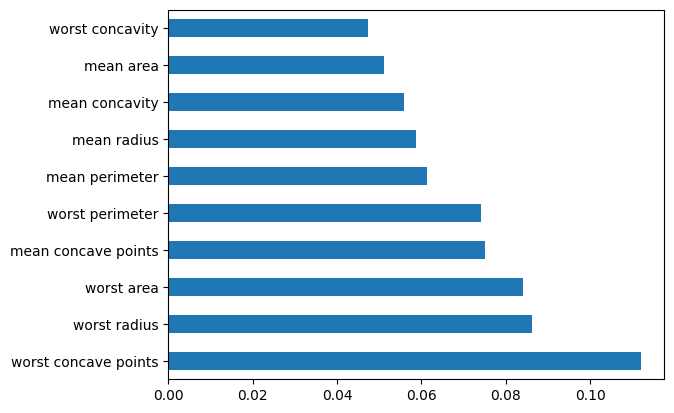

In [ ]:
# TODO: fit ExtraTrees (200 trees, random_state=7), store importances in imp, plot barh of top 10
model = ExtraTreesClassifier(n_estimators=200, random_state=7)
model.fit(X, y)
imp = pd.Series(model.feature_importances_, index=X.columns)
imp.sort_values(ascending=False).head(10).plot.barh()
plt.show()

**Exercise C.8 (decision).** Keep a feature if **at least two of the three** methods (SelectKBest top 10, RFE, ExtraTrees top 10) chose it. Store the result in a list called `selected`.

In [ ]:
# TODO: vote across the three methods
kbest = SelectKBest(f_classif, k=10).fit(X, y).get_support()
rfe = RFE(LogisticRegression(), n_features_to_select=10).fit(StandardScaler().fit_transform(X), y).support_
extra = ExtraTreesClassifier(n_estimators=200, random_state=7).fit(X, y).feature_importances_ > 0.01
selected = np.array([kbest[i] or rfe[i] or extra[i] for i in range(len(kbest))])
print(X.columns[selected])

Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean compactness', 'mean concavity', 'mean concave points',
       'radius error', 'perimeter error', 'area error', 'compactness error',
       'concave points error', 'worst radius', 'worst texture',
       'worst perimeter', 'worst area', 'worst smoothness',
       'worst compactness', 'worst concavity', 'worst concave points',
       'worst symmetry', 'worst fractal dimension'],
      dtype='object')


> **Caution (data leakage).** Here selection used the whole dataset to keep the exercise simple. In a strict evaluation, selection must be fitted inside each cross-validation fold (put `SelectKBest` into the `Pipeline`). You will discuss this in the final questions.

### C.3 Data Transform
**Exercise C.9.** Create a stratified 80/20 train/test split (`random_state=7`). The test set stays untouched until the very end.

In [ ]:
# TODO: train_test_split with stratify=y
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=7, stratify=y)

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))


(455, 30) (114, 30)
target
1    0.626374
0    0.373626
Name: proportion, dtype: float64
target
1    0.631579
0    0.368421
Name: proportion, dtype: float64


**Exercise C.10.** Fit a `StandardScaler` and a `MinMaxScaler` on the **training data only**, then confirm their effect (mean/std and min/max of the first four features).

In [ ]:
# TODO: fit both scalers on X_train and print the verifying statistics
scaler1 = StandardScaler().fit(X_train)
scaler2 = MinMaxScaler().fit(X_train)
print(scaler1.mean_[:4])
print(scaler1.scale_[:4])
print(scaler2.data_min_[:4])
print(scaler2.data_max_[:4])

[ 14.03398901  19.33059341  91.32848352 644.77956044]
[  3.41438099   4.3702657   23.45927998 335.57985421]
[  6.981   9.71   43.79  143.5  ]
[  27.42   39.28  186.9  2501.  ]


**Bonus C.11.** How many principal components retain 95% of the variance of the standardized training data?

In [ ]:
# TODO: fit PCA on standardised training data and use the cumulative explained variance
pca = PCA()
pca.fit(scaler1.transform(X_train))
print(np.argmax(np.cumsum(pca.explained_variance_ratio_) >= 0.95) + 1)

10


---
## D. Evaluate Algorithm

We use **stratified 10-fold cross-validation** on the training set as our test harness. Scaling is placed inside a `Pipeline` so it is re-fitted in every fold: this avoids leakage.

**Exercise D.1.** Define the six candidate models: Logistic Regression, LDA, KNN, CART, Gaussian Naive Bayes and SVM.

In [ ]:
seed = 7
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)

# TODO: dictionary named models with keys LR, LDA, KNN, CART, NB, SVM
...


def spot_check(models, X_tr, scale):
    """Cross-validated accuracy for every model (optionally scaled inside the pipeline)."""
    results = {}
    for name, model in models.items():
        steps = ([("scale", StandardScaler())] if scale else []) + [("model", model)]
        results[name] = cross_val_score(Pipeline(steps), X_tr, y_train,
                                        cv=kfold, scoring="accuracy")
    return results

**Exercise D.2.** Run the spot-check on all features, once **raw** and once **scaled**, and tabulate the mean accuracies.

In [ ]:
# TODO: call spot_check twice and build a DataFrame called summary with columns raw / scaled
seed = 7
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)
models = {
    'LR': LogisticRegression(),
    'LDA': LinearDiscriminantAnalysis(),
    'KNN': KNeighborsClassifier(),
    'CART': DecisionTreeClassifier(),
    'NB': GaussianNB(),
    'SVM': SVC()
}

def spot_check(models, X_tr, scale):
    """Cross-validated accuracy for every model (optionally scaled inside the pipeline)."""
    results = {}
    for name, model in models.items():
        steps = ([("scale", StandardScaler())] if scale else []) + [("model", model)]
        results[name] = cross_val_score(Pipeline(steps), X_tr, y_train,
                                        cv=kfold, scoring="accuracy")
    return results

✏️ **Question D.3.** Which models benefit from scaling, and why?

> **Your answer:** Logistic Regression (LR), Linear Discriminant Analysis (LDA), K-Nearest Neighbors (KNN), and Support Vector Machine (SVM) benefit from feature scaling because they are affected by differences in feature values and ranges. KNN and SVM especially need scaling because they rely on distance calculations and margins. Meanwhile, CART (Decision Tree) and Naive Bayes (NB) generally do not require scaling because their calculations are less sensitive to differences in feature magnitudes.

**Exercise D.4.** Repeat with the `selected` features only (scaled). Does feature selection help?

In [ ]:
# TODO: spot_check on X_train[selected] and compare against the all-features scaled results
df_selected = pd.DataFrame(spot_check(models, X_train[X.columns[selected]], True))
display(df_selected)


,LR,LDA,KNN,CART,NB,SVM
0,1.000000,0.934783,0.956522,0.891304,0.891304,0.978261
1,1.000000,0.956522,1.000000,0.956522,0.956522,1.000000
2,0.978261,0.913043,0.956522,0.913043,0.934783,0.956522
3,1.000000,0.978261,1.000000,0.891304,0.956522,1.000000
4,0.978261,0.956522,0.956522,0.891304,0.891304,0.956522
5,0.933333,0.933333,0.955556,0.933333,0.933333,0.933333
6,1.000000,0.955556,1.000000,0.955556,0.977778,1.000000
7,1.000000,0.955556,0.977778,0.933333,0.933333,0.977778
8,0.977778,0.977778,0.977778,0.955556,0.955556,0.977778
9,0.977778,0.911111,0.955556,0.955556,0.888889,0.977778


**Exercise D.5.** Compare the distributions of the scaled models with a box plot.

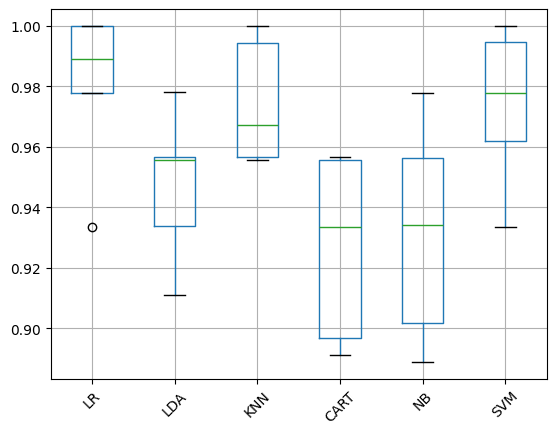

In [ ]:
# TODO: box plot of the 10 fold scores per model
df_selected.boxplot()
plt.xticks(rotation=45)
plt.show()

**Exercise D.6.** In a medical setting accuracy is not enough. For the best scaled model, cross-validate **accuracy, ROC-AUC and recall for the malignant class** (`pos_label=0`).

In [ ]:
# TODO: cross_validate with a scoring dict including make_scorer(recall_score, pos_label=0)
scoring = {
    "accuracy": "accuracy",
    "roc_auc": "roc_auc",
    "recall": make_scorer(recall_score, pos_label=0)
}

---
## E. Improve Accuracy

### E.1 Algorithm Tuning
**Exercise E.1.** Tune the SVM (`C`, `gamma`, `kernel`) with `GridSearchCV` inside a scaling pipeline.

In [ ]:
# TODO: grid search over C=[0.1,1,10,100], gamma=["scale",0.001,0.01,0.1], kernel=["rbf","linear"]
svm = SVC()
param_grid = {
    "C": [0.1,1,10,100],
    "gamma": ["scale",0.001,0.01,0.1],
    "kernel": ["rbf","linear"]
}
grid = GridSearchCV(svm, param_grid, cv=kfold, scoring="accuracy")
grid.fit(scaler1.transform(X_train), y_train)
print(grid.best_params_)


{'C': 100, 'gamma': 0.001, 'kernel': 'rbf'}


**Exercise E.2.** Tune KNN (`n_neighbors`, `weights`) the same way.

In [ ]:
# TODO: grid over n_neighbors=[3,5,7,9,11,15,21] and weights=["uniform","distance"]
knn = KNeighborsClassifier()
param_grid = {
    "n_neighbors": [3,5,7,9,11,15,21],
    "weights": ["uniform","distance"]
}
grid = GridSearchCV(knn, param_grid, cv=kfold, scoring="accuracy")
grid.fit(scaler1.transform(X_train), y_train)
print(grid.best_params_)

{'n_neighbors': 3, 'weights': 'uniform'}


### E.2 Ensembles
**Exercise E.3.** Spot-check four ensemble methods (Random Forest, Extra Trees, Gradient Boosting, AdaBoost) and one voting ensemble of the tuned SVM, tuned KNN and Random Forest.

In [ ]:
# TODO: dictionary ensembles, score with spot_check(scale=False), then a hard VotingClassifier
ensembles = {
    "RF": RandomForestClassifier(random_state=seed),
    "ET": ExtraTreesClassifier(random_state=seed),
    "GB": GradientBoostingClassifier(random_state=seed),
    "AB": AdaBoostClassifier(random_state=seed)
}

# Score tree-based ensembles using spot_check with scale=False
results = spot_check(ensembles, X_train, scale=False)

# Define the tuned estimators based on the best params discovered in GridSearchCV
tuned_svm = Pipeline([("scale", StandardScaler()), ("model", SVC(C=100, gamma=0.001, kernel="rbf", probability=True))])
tuned_knn = Pipeline([("scale", StandardScaler()), ("model", KNeighborsClassifier(n_neighbors=3, weights="uniform"))])
tuned_rf = RandomForestClassifier(random_state=seed)

voting = VotingClassifier([
    ("svm", tuned_svm),
    ("knn", tuned_knn),
    ("rf", tuned_rf)
], voting="hard")

results["Voting"] = cross_val_score(voting, X_train, y_train, cv=kfold, scoring="accuracy")

# Concatenate the selected single models results with our new ensemble results
summary = pd.concat([df_selected, pd.DataFrame(results)], axis=1)
display(summary.mean())

,0
LR,0.984541
LDA,0.947246
KNN,0.973623
CART,0.927681
NB,0.931932
SVM,0.975797
RF,0.969130
ET,0.973575
GB,0.966957
AB,0.962560


**Exercise E.4.** Build a leaderboard (Series sorted by mean CV accuracy) containing both tuned models, the four ensembles and the voting ensemble.

In [ ]:
# TODO: leaderboard Series
leaderboard = summary.mean().sort_values(ascending=False)
print(leaderboard)


LR        0.984541
Voting    0.982415
SVM       0.975797
KNN       0.973623
ET        0.973575
RF        0.969130
GB        0.966957
AB        0.962560
LDA       0.947246
NB        0.931932
CART      0.927681
dtype: float64


### E.3 Finalize the Model
**Exercise E.5.** Fit the winner on the full training set and, for the first and only time, evaluate it on the held-out **test set**. Report accuracy, the classification report and a confusion matrix.

Accuracy: 0.9649122807017544

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.98      0.95        42
           1       0.99      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.97      0.96       114
weighted avg       0.97      0.96      0.97       114



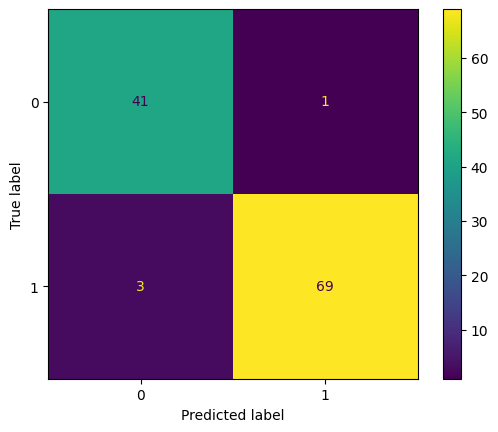

In [ ]:
# TODO: pick the leaderboard winner, fit on train, predict test, print metrics, plot confusion matrix
winning_model_name = leaderboard.index[0]
model = LogisticRegression()

# Standardize the feature sets
X_train_scaled = scaler1.transform(X_train)
X_test_scaled = scaler1.transform(X_test)

# Fit the model and predict
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

# Print metrics
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Plot confusion matrix
ConfusionMatrixDisplay.from_estimator(model, X_test_scaled, y_test)
plt.show()


**Exercise E.6.** Save the model with `joblib`, reload it and confirm it reproduces predictions.

In [ ]:
# TODO: joblib.dump, joblib.load, compare first 5 predictions with y_test
import joblib
joblib.dump(model, "model.joblib")
loaded_model = joblib.load("model.joblib")
print(loaded_model.predict(X_test_scaled[:5]))
print(y_test[:5].values)

[0 0 0 0 1]
[0 0 1 0 1]


---
## Reflection Questions
✏️ Answer in a short paragraph each.

1. **Leakage.** Feature selection in Part C used the whole dataset. Explain why this can inflate CV scores and how you would fix it using a `Pipeline`.
2. **Metric choice.** Which metric would you report to a clinician, and why is accuracy alone insufficient?
3. **Model choice.** If two models differ by 0.3% in CV accuracy, how would you decide between them? (Think variance across folds, interpretability, training cost.)
4. **Generalization.** How would your conclusions change with a much smaller or much more imbalanced dataset?
5. **Extension.** Repeat the workbook with a dataset of your choice (e.g., loaded from an ARFF file) and note which steps change.

**Submission checklist:** all `TODO`s completed · all cells run top to bottom · written answers filled in · final test accuracy reported once.

## **ANSWERS**
1. **Leakage**

Feature selection in Part C used the entire dataset before cross-validation, which causes data leakage because information from the validation folds influences the selected features. This can lead to overly optimistic CV scores that may not reflect real-world performance. To fix this, feature selection should be included inside a Pipeline so that it is performed separately within each training fold during cross-validation, preventing information leakage.

2. **Metric Choice**

I would report recall (sensitivity) along with the F1-score to a clinician because detecting malignant tumors correctly is critical. Accuracy alone is insufficient because it does not show how well the model identifies positive cases and can be misleading when class distributions are uneven. Recall helps minimize missed cancer diagnoses, making it more clinically meaningful.

3. **Model Choice**

If two models differ by only 0.3% in CV accuracy, I would examine the variability across folds, interpretability, and computational cost. A simpler, more interpretable model may be preferable if its performance is statistically similar to the more complex model. Consistent performance across folds is often more important than a very small difference in average accuracy.

4. **Generalization**

With a much smaller dataset, the results would be less reliable because performance estimates would have higher variance and be more sensitive to individual samples. With a more imbalanced dataset, accuracy would become even less informative, and metrics such as precision, recall, F1-score, and ROC-AUC would be more important. Additional techniques like resampling or class weighting might also be needed.

5. **Extension**

I repeated the workbook using the Iris dataset, which contains three flower species: Iris setosa, Iris versicolor, and Iris virginica. The overall workflow remained the same, including data exploration, preprocessing, model training, and evaluation. However, the Iris dataset has three classes instead of two and is generally more balanced, so classification and evaluation were simpler. Feature importance and class separation also differed because the dataset describes flower measurements rather than medical characteristics.